## Clustering TEI editions based on XML tag branches

We want to keep the analysis logic exactly the same, so there will be little new difficult stuff here. But we want to apply that logic at the edition level. This requires us to collect all XML documents in one folder into one (at least) well-formed XML-document. We can skip validation etc. It is not important in case we are just counting branches, but the parser should not quit because of unwell-formed XML.

In [17]:
import os

In [1]:
from pathlib import Path

dir_paths = [p for p in Path('./data/document_level').iterdir() if p.is_dir()]

print( dir_paths )


[PosixPath('data/document_level/CURSUS-OnlineResourceOfMedievalLiturgicalTexts'), PosixPath('data/document_level/CoReMa'), PosixPath('data/document_level/Chartes-de-labbaye-de-Saint-Denis'), PosixPath('data/document_level/Van-gogh'), PosixPath('data/document_level/Digital-marco-polo'), PosixPath('data/document_level/leopardi(_)'), PosixPath('data/document_level/beckettarchive'), PosixPath('data/document_level/Faust'), PosixPath('data/document_level/4earlyChanTextsFromDunhuang_aTEIbasedEdition2017'), PosixPath('data/document_level/Kaiserchronik'), PosixPath('data/document_level/Lyrik-des-deutschen-Mittelalters'), PosixPath('data/document_level/Der arme Heinrich'), PosixPath('data/document_level/Petrarchive'), PosixPath('data/document_level/Chronik-Ulrich-Richental'), PosixPath('data/document_level/saba')]


In [2]:
dir_path = dir_paths[4]
dir_path

PosixPath('data/document_level/Digital-marco-polo')

Next is just our familiar parser from the second notebook.

In [3]:
from xml.parsers import expat

def branch_text_positions(xml_string):
    
    parser = expat.ParserCreate()

    results = []
    stack = []

    text_pos = 0  # position in tag-stripped text

    def to_branch( name ):
        tag_names = [ item['tag'] for item in stack ]
        tag_names.append( name )
        return '.'.join( tag_names )

    def start(name, attrs):
        nonlocal text_pos
        stack.append({
            "tag": name,
            "start": text_pos
        })

    def end(name):
        nonlocal text_pos
        item = stack.pop()
        item['tag'] = to_branch( item['tag'] )
        item['end'] = text_pos
        results.append(item)

    def char_data(data):
        nonlocal text_pos
        text_pos += len(data)

    parser.StartElementHandler = start
    parser.EndElementHandler = end
    parser.CharacterDataHandler = char_data

    parser.Parse(xml_string)

    return results

There are three files in the Marco Polo edition. Can we just concatenate these?

In [4]:
import glob

three_xml_file_paths = glob.glob( './data/document_level/Digital-marco-polo/*.xml')

unique_branches = {}

for xml_file_path in three_xml_file_paths:
    with open( xml_file_path, 'r' ) as xml_file:
        xml = xml_file.read()
        branches = branch_text_positions( xml )
        branches_unique = set( [ branch['tag'] for branch in branches ] )
        unique_branches[xml_file_path] = branches_unique

unique_branches

{'./data/document_level/Digital-marco-polo/cgm696_master.xml': {'TEI',
  'TEI.teiHeader',
  'TEI.teiHeader.fileDesc',
  'TEI.teiHeader.fileDesc.publicationStmt',
  'TEI.teiHeader.fileDesc.publicationStmt.p',
  'TEI.teiHeader.fileDesc.sourceDesc',
  'TEI.teiHeader.fileDesc.sourceDesc.msDesc',
  'TEI.teiHeader.fileDesc.sourceDesc.msDesc.msIdentifier',
  'TEI.teiHeader.fileDesc.sourceDesc.msDesc.msIdentifier.idno',
  'TEI.teiHeader.fileDesc.sourceDesc.msDesc.msIdentifier.repository',
  'TEI.teiHeader.fileDesc.sourceDesc.msDesc.msIdentifier.settlement',
  'TEI.teiHeader.fileDesc.titleStmt',
  'TEI.teiHeader.fileDesc.titleStmt.respStmt',
  'TEI.teiHeader.fileDesc.titleStmt.respStmt.name',
  'TEI.teiHeader.fileDesc.titleStmt.respStmt.resp',
  'TEI.teiHeader.fileDesc.titleStmt.title',
  'TEI.text',
  'TEI.text.back',
  'TEI.text.back.xi:include',
  'TEI.text.back.xi:include.xi:fallback',
  'TEI.text.back.xi:include.xi:fallback.body',
  'TEI.text.back.xi:include.xi:fallback.body.p',
  'TEI.tex

Are there differences so we can test?

In [5]:
list( unique_branches.keys() )

['./data/document_level/Digital-marco-polo/cgm696_master.xml',
 './data/document_level/Digital-marco-polo/cgm252_master.xml',
 './data/document_level/Digital-marco-polo/realiaDI.xml']

In [6]:
first_file = unique_branches[ list( unique_branches.keys() )[0] ]
second_file = unique_branches[ list( unique_branches.keys() )[1] ]

print( len( first_file ) )
print( len( second_file ) )

print( len( first_file.intersection( second_file ) ) )

81
56
52


Great there are differences. There are 5 branches in the second file that do not exist in the first. We can use this knowledge to check if our parser still returns the right result if we just bluntly concatenate two XML files.

In [7]:
three_xml_file_paths = glob.glob( './data/document_level/Digital-marco-polo/*.xml')

unique_branches = {}
xml = ''

for xml_file_path in three_xml_file_paths[0:2]:
    with open( xml_file_path, 'r' ) as xml_file:
        xml += xml_file.read()
        print( len( xml ) )

branches = branch_text_positions( xml )
branches_unique = set( [ branch['tag'] for branch in branches ] )
unique_branches[xml_file_path] = branches_unique

len( unique_branches)

555316
593366


ExpatError: junk after document element: line 7205, column 0

Okay. Darn. We can't.

So, we'll need to take the long route: we parse each XML and concatenate each `TEI/text` element to the last `TEI/text` element in the first file.

In [8]:
from lxml import etree

TEI_NS = 'http://www.tei-c.org/ns/1.0'

def merge_tei(file_paths):
    # Parse the first file — this becomes our base document
    tree = etree.parse(file_paths[0])
    root = tree.getroot()

    # Find all <text> children of <TEI>, namespace-agnostic
    def find_texts(elem):
        return elem.xpath("./*[local-name()='text']")

    base_texts = find_texts(root)
    if not base_texts:
        raise ValueError(f'No <text> element in {file_paths[0]}')

    # Position to insert after the current last <text>
    insert_at = list(root).index(base_texts[-1]) + 1

    # For each additional file, grab its <text> elements and append
    for path in file_paths[1:]:
        other_root = etree.parse(path).getroot()
        for t in find_texts(other_root):
            root.insert(insert_at, t)
            insert_at += 1

    return etree.tostring(
        tree,
        pretty_print=True,
        xml_declaration=True,
        encoding='UTF-8',
    ).decode('utf-8')


In [9]:
combined_xml = merge_tei( three_xml_file_paths[0:2] )
print( combined_xml )

<?xml version='1.0' encoding='UTF-8'?>
<?xml-model href="punteggiatura.rng" type="application/xml" schematypens="http://relaxng.org/ns/structure/1.0"?>
<?xml-model href="http://www.tei-c.org/release/xml/tei/custom/schema/relaxng/tei_all.rng" type="application/xml" schematypens="http://purl.oclc.org/dsdl/schematron"?>
<TEI xmlns="http://www.tei-c.org/ns/1.0" xmlns:p="punteggiatura">
    <teiHeader>
        <fileDesc>
            <titleStmt>
                <title>Cgm 696</title>
                <respStmt>
                    <resp>Edited by</resp>
                    <name ref="#elisa">Elisa Cugliana</name>
                </respStmt>
            </titleStmt>
            <publicationStmt>
                <p>Doctoral dissertation</p>
            </publicationStmt>
            <sourceDesc>
                <msDesc>
                    <msIdentifier>
                        <settlement>München</settlement>
                        <repository>BSB</repository>
                        <idno>cg

In [10]:
len( set( [ branch['tag'] for branch in branch_text_positions(combined_xml) ] ) )

85

Hmmm.. I'd expected 86 branches. I can not readily think up a reason why I could mis a branch. But do we really care 'at this scale'? No.

But looking especailly at the files in the COREMA directory, I think this approach would ignore a lot of information. Those files have elaborate manuscript descriptiogn in the TEI-header, and they have `<facsimile>` at the same level as `<text>`. So, it is probably better to just concatenate anything between <TEI></TEI> in any file in a folder into one embrancing <TEI></TEI>.

In [11]:
from lxml import etree
from copy import deepcopy

def merge_tei(file_paths):
    parser = etree.XMLParser(collect_ids=False)

    first_root = etree.parse(file_paths[0], parser).getroot()
    new_root = etree.Element(
        first_root.tag,
        attrib=first_root.attrib,
        nsmap=first_root.nsmap,
    )

    for path in file_paths:
        root = etree.parse(path, parser).getroot()
        for child in root:
            new_root.append(deepcopy(child))

    return etree.tostring(
        new_root,
        pretty_print=True,
        xml_declaration=True,
        encoding='UTF-8',
    ).decode('utf-8')

In [12]:
combined_xml = merge_tei( three_xml_file_paths[0:2] )
print( combined_xml )

<?xml version='1.0' encoding='UTF-8'?>
<TEI xmlns="http://www.tei-c.org/ns/1.0" xmlns:p="punteggiatura"><teiHeader>
        <fileDesc>
            <titleStmt>
                <title>Cgm 696</title>
                <respStmt>
                    <resp>Edited by</resp>
                    <name ref="#elisa">Elisa Cugliana</name>
                </respStmt>
            </titleStmt>
            <publicationStmt>
                <p>Doctoral dissertation</p>
            </publicationStmt>
            <sourceDesc>
                <msDesc>
                    <msIdentifier>
                        <settlement>München</settlement>
                        <repository>BSB</repository>
                        <idno>cgm 696</idno>
                    </msIdentifier>
                </msDesc>
            </sourceDesc>
        </fileDesc>
    </teiHeader>
    <text>
        <front>
            <div>
                <listWit>
                    <witness xml:id="cgm696">BSB cgm 696</witness>
         

In [13]:
len( set( [ branch['tag'] for branch in branch_text_positions(combined_xml) ] ) )

85

Nice. Now let's see if it works for the COREMA stuff.

In [14]:
corema_xml_file_paths = glob.glob( './data/document_level/CoReMa/**/*.xml')
print( len( corema_xml_file_paths ) )
corema_xml_file_paths

64


['./data/document_level/CoReMa/manuscripts/Wo8.xml',
 './data/document_level/CoReMa/manuscripts/Wo9.xml',
 './data/document_level/CoReMa/manuscripts/A1.xml',
 './data/document_level/CoReMa/manuscripts/M2.xml',
 './data/document_level/CoReMa/manuscripts/M1.xml',
 './data/document_level/CoReMa/manuscripts/Ha1.xml',
 './data/document_level/CoReMa/manuscripts/M5.xml',
 './data/document_level/CoReMa/manuscripts/Db1.xml',
 './data/document_level/CoReMa/manuscripts/St1.xml',
 './data/document_level/CoReMa/manuscripts/M6.xml',
 './data/document_level/CoReMa/manuscripts/M11.xml',
 './data/document_level/CoReMa/manuscripts/Pr1.xml',
 './data/document_level/CoReMa/manuscripts/M10.xml',
 './data/document_level/CoReMa/manuscripts/M7.xml',
 './data/document_level/CoReMa/manuscripts/K1.xml',
 './data/document_level/CoReMa/manuscripts/Ste1.xml',
 './data/document_level/CoReMa/manuscripts/Pa1.xml',
 './data/document_level/CoReMa/manuscripts/Ka1.xml',
 './data/document_level/CoReMa/manuscripts/Ka3.xml',

In [15]:
combined_xml = merge_tei( corema_xml_file_paths )
print( combined_xml )

<?xml version='1.0' encoding='UTF-8'?>
<TEI xmlns="http://www.tei-c.org/ns/1.0"><teiHeader>
    <fileDesc>
      <titleStmt>
        <title>Electronic transcription of Wolfenbüttel, Herzog August Bibliothek Cod.
					Guelf. 51 Aug 4°</title>
      </titleStmt>
      <editionStmt>
        <edition>Hyperdiplomatische Basistranskription der Handschrift Wolfenbüttel, Herzog
					August Bibliothek Cod. Guelf. 51 Aug 4°</edition>
        <editor>
          <forename>Barbara</forename>
          <surname>Denicolò</surname>
        </editor>
        <principal>
          <forename>Helmut W.</forename>
          <surname>Klug</surname>
        </principal>
        <funder ref="https://www.uni-salzburg.at/index.php?id=205415">Salzburg University,
					Department of History</funder>
      </editionStmt>
      <publicationStmt>
        <publisher>
          <ref target="https://informationsmodellierung.uni-graz.at"/>
          <orgName ref="http://d-nb.info/gnd/1137284463">ZIM-ACDH, Universität
		

Okay, that all seems to work. So now we can combine all XML files under one directory into one large file, which represents the edition as a whole. We do that, and save the transformed files. 

In [18]:
for dir_path in dir_paths:
    xml_file_paths = glob.glob( os.path.join( str( dir_path ), '**/*.xml' ), recursive=True )
    combined_xml = merge_tei( xml_file_paths )
    with open( './data/edition_level/{file_name}.xml'.format( file_name=str(dir_path).split('/')[-1] ), 'w' ) as xml_out_file:
        xml_out_file.write( combined_xml )



### Now we return to the code of the second notebook

In [19]:
from xml.parsers import expat

def branch_text_positions(xml_string):
    
    parser = expat.ParserCreate()

    results = []
    stack = []

    text_pos = 0  # position in tag-stripped text

    def to_branch( name ):
        tag_names = [ item['tag'] for item in stack ]
        tag_names.append( name )
        return '.'.join( tag_names )

    def start(name, attrs):
        nonlocal text_pos
        stack.append({
            "tag": name,
            "start": text_pos
        })

    def end(name):
        nonlocal text_pos
        item = stack.pop()
        item['tag'] = to_branch( item['tag'] )
        item['end'] = text_pos
        results.append(item)

    def char_data(data):
        nonlocal text_pos
        text_pos += len(data)

    parser.StartElementHandler = start
    parser.EndElementHandler = end
    parser.CharacterDataHandler = char_data

    parser.Parse(xml_string)

    return results

In [20]:
from glob import glob
import pandas
from random import randrange

bp_dfs = {}

file_paths = glob( './data/edition_level/*.xml' )

print( len( file_paths ) )

15


In [21]:
file_count = 0

for file_path in file_paths:
    with open( file_path, 'r' ) as xml_file:
        try:
            xml = xml_file.read()
        except Exception as e:
            print( '')
            print( str( e ), file_path )
            with open( file_path, 'r', encoding='latin-1' ) as xml_file:
                xml = xml_file.read()
        bp = branch_text_positions( xml )
        bp_df = pandas.DataFrame( bp )
        bp_dfs[ file_path ] = bp_df
    file_count += 1
    print( file_count, end='' )
    if file_count % 30 == 0:
        print( ' ' )
    else:
        print( ', ', end='' )
        
# Quick check…
result_from_one_file = list( bp_dfs.keys() )[ randrange( len( file_paths ) ) ]
print( '\n\n', result_from_one_file, '=>' )
bp_dfs[ result_from_one_file ]


1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 

 ./data/edition_level/beckettarchive.xml =>


,tag,start,end
0,TEI.teiHeader.fileDesc.titleStmt.title,30,47
1,TEI.teiHeader.fileDesc.titleStmt.author,60,74
2,TEI.teiHeader.fileDesc.titleStmt.principal,87,101
3,TEI.teiHeader.fileDesc.titleStmt.funder.name,130,165
4,TEI.teiHeader.fileDesc.titleStmt.funder.addres...,200,227
...,...,...,...
9800,TEI.text.body.div.stage,302002,302351
9801,TEI.text.body.div,256849,302361
9802,TEI.text.body,256839,302368
9803,TEI.text,256704,302372


In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas

def create_branches_vectorizer():
    return TfidfVectorizer(
        token_pattern = None,
        tokenizer = lambda s: s.split( '.' ),  # split on period
        lowercase = False                      # keep as-is
    )


In [23]:
weights_docs = {}

for path_name, bp_df in bp_dfs.items():
    vectorizer = create_branches_vectorizer()
    weights_doc = vectorizer.fit_transform( bp_df[ 'tag' ] )
    df_tfidf = pandas.DataFrame( weights_doc.toarray(), columns=vectorizer.get_feature_names_out() )
    df_combined = pandas.concat( [bp_df, df_tfidf.mean( axis=1 )], axis=1 )
    df_combined.rename( columns={0:'weight'}, inplace=True )
    sorted_by_weight = ( 
        df_combined.groupby( 'tag', as_index=False )
            .agg( mean_weight=( 'weight', 'mean' ),  # .agg( new_column_name = ( 'existing_column_name', 'function_to_apply' )
                count=( 'weight', 'count' ) )
            .sort_values( by='mean_weight', ascending=False )
            .reset_index( drop=True )
        )
    weights_docs[ path_name ] = sorted_by_weight

In [24]:
weights_docs

{'./data/edition_level/Digital-marco-polo.xml':                                                    tag  mean_weight  count
 0    TEI.teiHeader.fileDesc.sourceDesc.msDesc.msIde...     0.046832      2
 1    TEI.teiHeader.fileDesc.sourceDesc.msDesc.msIde...     0.046832      2
 2    TEI.teiHeader.fileDesc.sourceDesc.msDesc.msIde...     0.046832      2
 3                               TEI.text.body.div.p.lb     0.045463   5886
 4       TEI.text.body.div.listPlace.place.location.geo     0.044888    164
 ..                                                 ...          ...    ...
 99                                  TEI.text.front.div     0.024895      1
 100                                      TEI.text.back     0.023356      2
 101                                     TEI.text.front     0.022906      1
 102                                      TEI.teiHeader     0.021487      3
 103                                                TEI     0.018868      1
 
 [104 rows x 3 columns],
 './data/editi

In [25]:
doc_vectorizer = TfidfVectorizer(
    token_pattern = None,
    tokenizer = lambda s: s.split( ' ' ),  # split on space
    lowercase = False                      # keep as-is
)

branch_docs = []

for key in weights_docs.keys():
    bp_df = bp_dfs[key]
    print( f'{len( bp_df['tag'].unique() )} unique branches in {key}' )
    branch_doc = ' '.join( bp_df['tag'].values )
    branch_docs.append( branch_doc )

tfidf_docs = doc_vectorizer.fit_transform( branch_docs )

104 unique branches in ./data/edition_level/Digital-marco-polo.xml
265 unique branches in ./data/edition_level/Chartes-de-labbaye-de-Saint-Denis.xml
186 unique branches in ./data/edition_level/Petrarchive.xml
92 unique branches in ./data/edition_level/leopardi(_).xml
541 unique branches in ./data/edition_level/beckettarchive.xml
47 unique branches in ./data/edition_level/Chronik-Ulrich-Richental.xml
230 unique branches in ./data/edition_level/Der arme Heinrich.xml
120 unique branches in ./data/edition_level/Lyrik-des-deutschen-Mittelalters.xml
93 unique branches in ./data/edition_level/4earlyChanTextsFromDunhuang_aTEIbasedEdition2017.xml
14 unique branches in ./data/edition_level/CURSUS-OnlineResourceOfMedievalLiturgicalTexts.xml
92 unique branches in ./data/edition_level/Van-gogh.xml
791 unique branches in ./data/edition_level/CoReMa.xml
121 unique branches in ./data/edition_level/Faust.xml
155 unique branches in ./data/edition_level/Kaiserchronik.xml
258 unique branches in ./data/edi

In [26]:
branch_doc

'TEI.teiHeader.fileDesc.titleStmt.title TEI.teiHeader.fileDesc.titleStmt.title TEI.teiHeader.fileDesc.titleStmt.author TEI.teiHeader.fileDesc.titleStmt.respStmt.resp TEI.teiHeader.fileDesc.titleStmt.respStmt.name TEI.teiHeader.fileDesc.titleStmt.respStmt.name TEI.teiHeader.fileDesc.titleStmt.respStmt TEI.teiHeader.fileDesc.titleStmt.respStmt.resp TEI.teiHeader.fileDesc.titleStmt.respStmt.name TEI.teiHeader.fileDesc.titleStmt.respStmt TEI.teiHeader.fileDesc.titleStmt TEI.teiHeader.fileDesc.editionStmt.edition.interpGrp.interp TEI.teiHeader.fileDesc.editionStmt.edition.interpGrp TEI.teiHeader.fileDesc.editionStmt.edition TEI.teiHeader.fileDesc.editionStmt TEI.teiHeader.fileDesc.publicationStmt.authority TEI.teiHeader.fileDesc.publicationStmt TEI.teiHeader.fileDesc.sourceDesc.listWit.witness.msDesc.msIdentifier.settlement TEI.teiHeader.fileDesc.sourceDesc.listWit.witness.msDesc.msIdentifier.repository TEI.teiHeader.fileDesc.sourceDesc.listWit.witness.msDesc.msIdentifier.idno TEI.teiHeader

In [27]:
tfidf_docs.shape

(15, 2720)

In [28]:
from scipy.sparse import lil_matrix

# Create a matrix the same size of the TF-IDF that contains all documents.
W = lil_matrix( tfidf_docs.shape )

for i, weights_doc in enumerate( weights_docs.values() ):

    # Get the weights
    branch_weights = list( zip( weights_doc['tag'], weights_doc['mean_weight'] ) )

    # Fill W with weights for each document
    for branch_weight in branch_weights:
        if branch_weight[0] in doc_vectorizer.vocabulary_:
            # find the column index of the feature ('tag') in the documents TF-IDF
            j = doc_vectorizer.vocabulary_[branch_weight[0]]
            # ut the weight on the same index in the weights matrix
            W[i, j] = branch_weight[1]


tfidf_docs_weighted = tfidf_docs.multiply( W )
print( tfidf_docs.toarray() )
print( tfidf_docs_weighted.toarray() )

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [29]:
print( tfidf_docs_weighted.nnz )
print( tfidf_docs_weighted.shape[0] * tfidf_docs_weighted.shape[1] )

3109
40800


In [30]:
file_paths

['./data/edition_level/Digital-marco-polo.xml',
 './data/edition_level/Chartes-de-labbaye-de-Saint-Denis.xml',
 './data/edition_level/Petrarchive.xml',
 './data/edition_level/leopardi(_).xml',
 './data/edition_level/beckettarchive.xml',
 './data/edition_level/Chronik-Ulrich-Richental.xml',
 './data/edition_level/Der arme Heinrich.xml',
 './data/edition_level/Lyrik-des-deutschen-Mittelalters.xml',
 './data/edition_level/4earlyChanTextsFromDunhuang_aTEIbasedEdition2017.xml',
 './data/edition_level/CURSUS-OnlineResourceOfMedievalLiturgicalTexts.xml',
 './data/edition_level/Van-gogh.xml',
 './data/edition_level/CoReMa.xml',
 './data/edition_level/Faust.xml',
 './data/edition_level/Kaiserchronik.xml',
 './data/edition_level/saba.xml']

/Users/joris/Workspace/THINK/conflint/representation/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


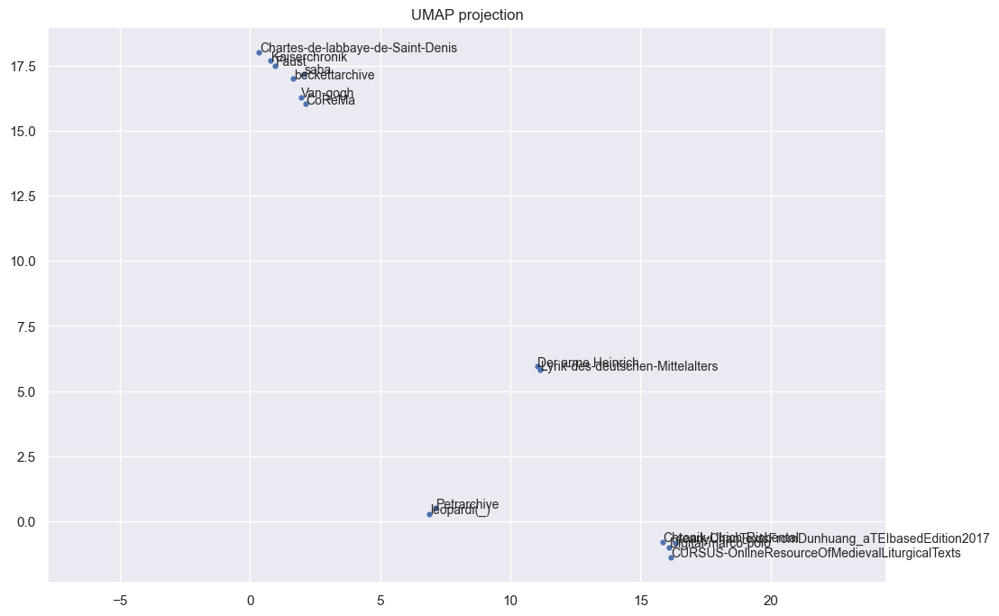

In [39]:
import umap
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

reducer = umap.UMAP(
    n_neighbors=2,
    min_dist=0.0, 
    n_components=2,
    metric='cosine', 
    random_state=34
)
embedding = reducer.fit_transform( tfidf_docs_weighted )

plt.figure( figsize=(12, 8) )
plt.scatter( embedding[:, 0], embedding[:, 1], s=12 )
plt.gca().set_aspect( 'equal', 'datalim' )
plt.title( 'UMAP projection' )
offset = 0.03
for i in range( 0, len( embedding ) ):
    # We cluster individual files, but we label them at the edition level using the folder name.
    plt.text( embedding[i,0] + offset, embedding[i,1], f'{file_paths[i].split('/')[-1].split('.')[-2]}', size=10 )

plt.savefig( 'result_edition_level.png', dpi=300 )
plt.show()



The Silhouette Coefficient is calculated using the mean intra-cluster distance `(a)` and the mean nearest-cluster distance `(b)` for each sample. The Silhouette Coefficient for a sample is `(b - a) / max(a, b)`. To clarify, `b` is the distance between a sample and the nearest cluster that the sample is not a part of. Note that Silhouette Coefficient is only defined if number of labels is `2 <= n_labels <= n_samples - 1`.

This function returns the mean Silhouette Coefficient over all samples. To obtain the values for each sample, use silhouette_samples.

**The best value is 1 and the worst value is -1. Values near 0 indicate overlapping clusters.** Negative values generally indicate that a sample has been assigned to the wrong cluster, as a different cluster is more similar.

In [ ]:
from sklearn.metrics import silhouette_score
print( silhouette_score( tfidf_docs_weighted, labels, metric='cosine') )

0.0011812372758925034


Yes, this is bad. We do not have meaningful clusters. They basically overlap.

Still, we want to know on the basis of which features the clusters were formed. Maybe this tells us something about the hairline differences between the clusters.

In [68]:
from sklearn.cluster import KMeans
# or HDBSCAN if clusters are non-spherical / variable density

labels = KMeans( n_clusters=4, random_state=34 ).fit_predict( tfidf_docs_weighted )
# alternatively cluster the embedding: ...fit_predict(embedding)


In [104]:
from sklearn.cluster import HDBSCAN
labels = HDBSCAN( min_cluster_size=2, metric='cosine' ).fit_predict( tfidf_docs_weighted )

/Users/joris/Workspace/THINK/conflint/representation/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [100]:
import numpy as np

In [105]:
feature_names = np.array(doc_vectorizer.get_feature_names_out())

tfidf_docs_weighted_df = pandas.DataFrame( tfidf_docs_weighted.toarray() )
tfidf_docs_weighted_df['cluster'] = labels

cluster_editions = pandas.DataFrame( [ file_path.split('/')[-1].split('.')[-2] for file_path in file_paths ], index=labels )

print( feature_names )
print( 'Number of features:', len( feature_names ) )
display( cluster_editions )
tfidf_docs_weighted_df

['CURSUS' 'CURSUS.text' 'CURSUS.text.body' ...
 'div.text.body.div.ab.title.space' 'div.text.body.div.ab.unclear'
 'div.text.body.div.ab.unclear.pc']
Number of features: 2720


,0
1,Digital-marco-polo
-1,Chartes-de-labbaye-de-Saint-Denis
3,Petrarchive
3,leopardi(_)
2,beckettarchive
1,Chronik-Ulrich-Richental
0,Der arme Heinrich
0,Lyrik-des-deutschen-Mittelalters
-1,4earlyChanTextsFromDunhuang_aTEIbasedEdition2017
-1,CURSUS-OnlineResourceOfMedievalLiturgicalTexts


,0,1,2,3,4,5,6,7,8,9,...,2711,2712,2713,2714,2715,2716,2717,2718,2719,cluster
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,-1
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,3
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,3
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,2
5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0
7,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0
8,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000187,0.000182,0.000009,0.000103,0.000093,0.000033,0.000011,0.00029,0.000021,-1
9,0.000385,0.000545,0.000667,0.006164,0.099926,0.099142,0.107829,0.108747,0.108747,0.001165,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,-1


Looks good. Onward.

In [115]:
# Mean TF-IDF weight per term per cluster
cluster_means = tfidf_docs_weighted_df.groupby('cluster').mean()

# Top terms per cluster
report = ''
for idx, c in enumerate( cluster_means.index ):
    top = cluster_means.loc[c].sort_values(ascending=False).head(15)
    report += f'\n--- Cluster {idx} --- \n\nEditions:\n'
    for edition in cluster_editions.loc[c][0]:
        report += f'  * {edition}\n'
    report += '\n'
    for item in ( list( zip( feature_names[top.index.astype(int)], top[:15] ) ) ):
        report += f'({round( item[1], 4 ):.4f})  {item[0]}\n'

print( report )
with open( './report.md', 'w' ) as report_file:
    report_file.write( report )
        


--- Cluster 0 --- 

Editions:
  * Chartes-de-labbaye-de-Saint-Denis
  * 4earlyChanTextsFromDunhuang_aTEIbasedEdition2017
  * CURSUS-OnlineResourceOfMedievalLiturgicalTexts
  * Van-gogh
  * CoReMa
  * saba

(0.0181)  CURSUS.text.body.chapter.verse.reference.bookName
(0.0181)  CURSUS.text.body.chapter.verse.reference.verseNum
(0.0180)  CURSUS.text.body.chapter.verse.reference
(0.0167)  CURSUS.text.body.chapter.verse
(0.0165)  CURSUS.text.body.chapter.verse.l
(0.0062)  TEI.text.body.div.ab.lb
(0.0061)  div.text.body.div.ab.orig
(0.0045)  div.text.body.div.ab.pc
(0.0043)  div.text.body.div.ab.orig.g
(0.0034)  TEI.text.body.div.div.div.div.lg.l
(0.0024)  TEI.text.group.text.body.div.listWit.listWit.witness
(0.0023)  TEI.text.body.ab.seg.g
(0.0021)  TEI.text.body.div.ab.c
(0.0021)  TEI.text.body.div.div.div.div.div.lg.l
(0.0021)  TEI.text.body.div.ab

--- Cluster 1 --- 

Editions:
  * Der arme Heinrich
  * Lyrik-des-deutschen-Mittelalters

(0.0163)  TEI.text.body.div.lg.l.w
(0.0130)  TEI.te